In [3]:
# Imports + load Fashion-MNIST (Task 3-5)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist

np.random.seed(42)
tf.random.set_seed(42)

(x_train, _), (x_test, _) = fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn  = x_test.reshape(-1, 28, 28, 1)

x_train_flat = x_train.reshape(-1, 784)
x_test_flat  = x_test.reshape(-1, 784)

print("CNN input:", x_train_cnn.shape, "Flat input:", x_train_flat.shape)


CNN input: (60000, 28, 28, 1) Flat input: (60000, 784)


In [4]:
# Dense Autoencoder (baseline) - build + train

input_img = layers.Input(shape=(784,))
encoded = layers.Dense(128, activation="relu")(input_img)
encoded = layers.Dense(64, activation="relu")(encoded)

decoded = layers.Dense(128, activation="relu")(encoded)
decoded = layers.Dense(784, activation="sigmoid")(decoded)

dense_ae = tf.keras.Model(input_img, decoded, name="dense_autoencoder")
dense_ae.compile(optimizer="adam", loss="mse")
dense_ae.summary()

history_dense = dense_ae.fit(
    x_train_flat, x_train_flat,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

dense_test_loss = dense_ae.evaluate(x_test_flat, x_test_flat, verbose=0)
print("Dense AE Test Loss:", dense_test_loss)


Model: "dense_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0453 - val_loss: 0.0235
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0207 - val_loss: 0.0188
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0175 - val_loss: 0.0163
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0156 - val_loss: 0.0149
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0144 - val_loss: 0.0139
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0136 - val_loss: 0.0132
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0129 - val_loss: 0.0126
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0123 - val_loss: 0.0121
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0119 - val_loss: 0.0117
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0115 - val_loss: 0.0114
Dense AE Test Loss: 0.011426055803894997


In [5]:
# CNN Autoencoder - build + train

cnn_ae = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Encoder
    layers.Conv2D(32, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2), padding="same"),
    layers.Conv2D(16, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2), padding="same"),

    # Decoder
    layers.Conv2DTranspose(16, (3,3), strides=2, activation="relu", padding="same"),
    layers.Conv2DTranspose(32, (3,3), strides=2, activation="relu", padding="same"),
    layers.Conv2D(1, (3,3), activation="sigmoid", padding="same"),
], name="cnn_autoencoder")

cnn_ae.compile(optimizer="adam", loss="mse")
cnn_ae.summary()

history_cnn = cnn_ae.fit(
    x_train_cnn, x_train_cnn,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_cnn, x_test_cnn),
    verbose=1
)

cnn_test_loss = cnn_ae.evaluate(x_test_cnn, x_test_cnn, verbose=0)
print("CNN AE Test Loss:", cnn_test_loss)


Model: "cnn_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 16)     │         2,320 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │         4,640 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 25s 99ms/step - loss: 0.0381 - val_loss: 0.0125
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 24s 103ms/step - loss: 0.0111 - val_loss: 0.0103
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 92ms/step - loss: 0.0096 - val_loss: 0.0092
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 89ms/step - loss: 0.0086 - val_loss: 0.0083
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - loss: 0.0079 - val_loss: 0.0075
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - loss: 0.0071 - val_loss: 0.0069
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - loss: 0.0066 - val_loss: 0.0064
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 97ms/step - loss: 0.0061 - val_loss: 0.0060
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 23s 96ms/step - loss: 0.0058 - val_loss: 0.0057
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - loss: 0.0055 - val_loss: 0.0055
CNN AE Test Loss: 0.005460081156343222


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


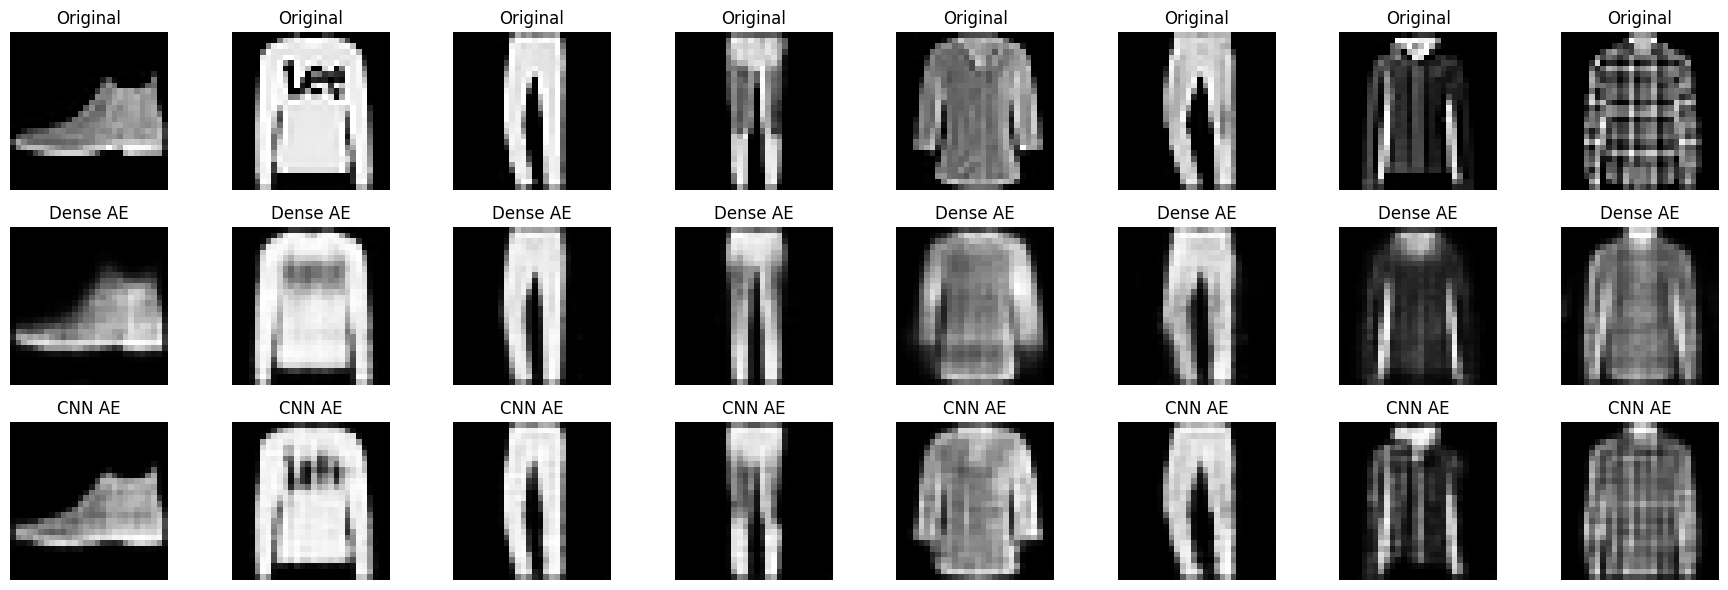

In [6]:
# Compare Dense AE vs CNN AE reconstructions

decoded_dense = dense_ae.predict(x_test_flat)
decoded_cnn   = cnn_ae.predict(x_test_cnn)

n = 8
plt.figure(figsize=(18, 6))

for i in range(n):
    # original
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # dense AE
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(decoded_dense[i].reshape(28, 28), cmap="gray")
    plt.title("Dense AE")
    plt.axis("off")

    # CNN AE
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_cnn[i].reshape(28, 28), cmap="gray")
    plt.title("CNN AE")
    plt.axis("off")

plt.tight_layout()
plt.show()
